In [ ]:
import pandas as pd;
import json
import missingno as msno
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path

import pandas as pd
import pandera.pandas as pa
from pandera.pandas import Check, Column, DataFrameSchema

In [434]:
df_dirty = pd.read_json("../data/raw/appdetails.json");


display(df_dirty.head(5));
display(df_dirty[df_dirty['success'] == False])


,appid,success,data
0,620,True,"{'type': 'game', 'name': 'Portal 2', 'steam_ap..."
1,413150,True,"{'type': 'game', 'name': 'Stardew Valley', 'st..."
2,1118200,True,"{'type': 'game', 'name': 'People Playground', ..."
3,400,True,"{'type': 'game', 'name': 'Portal', 'steam_appi..."
4,1794680,True,"{'type': 'game', 'name': 'Vampire Survivors', ..."


,appid,success,data
152,217980,False,NaN
551,1161870,False,NaN
878,1903370,False,NaN


In [435]:
rows = []
with open("../data/raw/appdetails.json", "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        
        item = json.loads(line)
        
        # Se o arquivo contiver listas de itens por linha, tratamos cada um:
        items_list = item if isinstance(item, list) else [item]
        
        for sub_item in items_list:
            if isinstance(sub_item, dict) and sub_item.get("success") and "data" in sub_item:
                row = sub_item["data"]
                row["appid"] = sub_item.get("appid")
                rows.append(row)

# Converte a lista de dicionários em um DataFrame estruturado
df_normalized_dirty = pd.DataFrame(rows)

# Exibe as primeiras linhas com as colunas abertas
display(df_normalized_dirty[['name', 'type', 'is_free', 'required_age']].head(5))

pd.set_option('display.max_columns', None)

display(df_normalized_dirty.head(1))



,name,type,is_free,required_age
0,Portal 2,game,False,0
1,Stardew Valley,game,False,12
2,People Playground,game,False,0
3,Portal,game,False,0
4,Vampire Survivors,game,False,0


,type,name,steam_appid,required_age,is_free,controller_support,dlc,detailed_description,about_the_game,short_description,supported_languages,header_image,capsule_image,capsule_imagev5,website,pc_requirements,mac_requirements,linux_requirements,developers,publishers,price_overview,packages,package_groups,platforms,metacritic,categories,genres,screenshots,movies,recommendations,achievements,release_date,support_info,background,background_raw,content_descriptors,ratings,appid,reviews,demos,legal_notice,ext_user_account_notice,fullgame,drm_notice
0,game,Portal 2,620,0,False,full,[323180],Portal 2 draws from the award-winning formula ...,Portal 2 draws from the award-winning formula ...,The &quot;Perpetual Testing Initiative&quot; h...,"English<strong>*</strong>, French<strong>*</st...",https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,http://www.thinkwithportals.com/,{'minimum': '<strong>Minimum:</strong><br><ul ...,{'minimum': '<strong>Minimum:</strong><br><ul ...,{'minimum': '<strong>Minimum:</strong><br><ul ...,[Valve],[Valve],"{'currency': 'BRL', 'initial': 3299, 'final': ...","[204528, 7877, 8187]","[{'name': 'default', 'title': 'Buy Portal 2', ...","{'windows': True, 'mac': False, 'linux': True}","{'score': 95, 'url': 'https://www.metacritic.c...","[{'id': 2, 'description': 'Single-player'}, {'...","[{'id': '1', 'description': 'Action'}, {'id': ...","[{'id': 0, 'path_thumbnail': 'https://shared.a...","[{'id': 5787, 'name': 'Portal 2 E3 Demo (Excur...",{'total': 390616},"{'total': 51, 'highlighted': [{'icon': 'SURVIV...","{'coming_soon': False, 'date': '18 Apr, 2011'}","{'url': 'http://steamcommunity.com/app/620', '...",https://store.akamai.steamstatic.com/images/st...,https://store.akamai.steamstatic.com/images/st...,"{'ids': [], 'notes': None}","{'usk': {'rating': '12'}, 'dejus': {'rating_ge...",620,NaN,NaN,NaN,NaN,NaN,NaN


In [436]:
display(df_normalized_dirty[df_normalized_dirty["name"].str.lower().str.startswith("the wi", na=False)])
pd.set_option('display.max_columns', 22)


,type,name,steam_appid,required_age,is_free,controller_support,dlc,detailed_description,about_the_game,short_description,supported_languages,header_image,capsule_image,capsule_imagev5,website,pc_requirements,mac_requirements,linux_requirements,developers,publishers,price_overview,packages,package_groups,platforms,metacritic,categories,genres,screenshots,movies,recommendations,achievements,release_date,support_info,background,background_raw,content_descriptors,ratings,appid,reviews,demos,legal_notice,ext_user_account_notice,fullgame,drm_notice
122,game,The Witcher 3: Wild Hunt - Complete Edition,292030,17,False,NaN,"[5006530, 1229320, 1233280, 1233340]",<h1>GET READY FOR AN EPIC WITCHER STORY FULL O...,"<p class=""bb_paragraph"" style=""text-align: cen...","You are Geralt of Rivia, mercenary monster sla...","English<strong>*</strong>, French<strong>*</st...",https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,https://www.thewitcher.com/witcher3,{'minimum': '<strong>Minimum:</strong><br><ul ...,[],[],[CD PROJEKT RED],[CD PROJEKT RED],"{'currency': 'USD', 'initial': 4999, 'final': ...",[68476],"[{'name': 'default', 'title': 'Buy The Witcher...","{'windows': True, 'mac': False, 'linux': False}","{'score': 93, 'url': 'https://www.metacritic.c...","[{'id': 2, 'description': 'Single-player'}, {'...","[{'id': '3', 'description': 'RPG'}]","[{'id': 0, 'path_thumbnail': 'https://shared.a...","[{'id': 257411256, 'name': 'The Witcher 3: Wil...",{'total': 833494},"{'total': 78, 'highlighted': [{'icon': '607858...","{'coming_soon': False, 'date': 'May 18, 2015'}","{'url': 'http://en.cdprojektred.com/support', ...",https://store.akamai.steamstatic.com/images/st...,https://shared.akamai.steamstatic.com/store_it...,"{'ids': [1, 5], 'notes': 'The Witcher 3: Wild ...","{'esrb': {'rating': 'm', 'descriptors': 'Blood...",292030,“ONE OF THE BEST GAMES EVER MADE”<br>10/10 – G...,NaN,"CD PROJEKT RED®, CD PROJEKT®, The Witcher® are...",NaN,NaN,NaN
446,dlc,The Witcher 3: Wild Hunt - Blood and Wine,378648,0,False,full,NaN,"<h1>Special Offer</h1><p><span class=""bb_img_c...",Blood and Wine is the final expansion for The ...,Become professional monster slayer Geralt of R...,"English<strong>*</strong>, French<strong>*</st...",https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,http://www.thewitcher.com,{'minimum': '<strong>Minimum:</strong><br><ul ...,[],[],[CD PROJEKT RED],[CD PROJEKT RED],NaN,NaN,[],"{'windows': True, 'mac': False, 'linux': False}","{'score': 92, 'url': 'https://www.metacritic.c...","[{'id': 2, 'description': 'Single-player'}, {'...","[{'id': '3', 'description': 'RPG'}]","[{'id': 0, 'path_thumbnail': 'https://shared.a...","[{'id': 256664412, 'name': 'Trailer', 'thumbna...",{'total': 9327},NaN,"{'coming_soon': False, 'date': '30 May, 2016'}","{'url': 'http://en.cdprojektred.com/support', ...",https://store.akamai.steamstatic.com/images/st...,https://shared.akamai.steamstatic.com/store_it...,"{'ids': [1, 5], 'notes': 'The Witcher 3: Wild ...","{'pegi': {'rating': '18'}, 'oflc': {'rating': ...",378648,NaN,NaN,"CD PROJEKT®, The Witcher® are registered trade...",NaN,"{'appid': '292030', 'name': 'The Witcher 3: Wi...",NaN
878,dlc,The Witcher 3: Wild Hunt - Expansion Pass,355880,0,False,full,NaN,The Expansion Pass secures your access to two ...,The Expansion Pass secures your access to two ...,The Witcher 3: Wild Hunt Expansion Pass secure...,"English<strong>*</strong>, French<strong>*</st...",https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,http://www.thewitcher.com,{'minimum': '<strong>Minimum:</strong><br><ul ...,{'minimum': '<strong>Minimum:</strong><br><ul ...,{'minimum': '<strong>Minimum:</strong><br><ul ...,[CD PROJEKT RED],[CD PROJEKT RED],NaN,Na

In [437]:
df_colunas_filtradas = df_normalized_dirty[['appid','type', 'name', 'required_age', 'is_free', 'dlc','packages','controller_support',
                                            'developers', 'publishers', 'pc_requirements', 'price_overview', 'metacritic',  
                                            'categories', 'genres', 'recommendations', 'achievements', 'release_date', 'ratings', 'supported_languages']]


# formatando colunas

df_colunas_filtradas['developers'] = df_colunas_filtradas['developers'].apply(
    lambda x: ', '.join(x) if isinstance(x, list) else str(x) if pd.notna(x) else ''
)

df_colunas_filtradas['publishers'] = df_colunas_filtradas['publishers'].apply(
    lambda x: ', '.join(x) if isinstance(x, list) else str(x) if pd.notna(x) else ''
)

df_colunas_filtradas['metacritic'] = df_colunas_filtradas['metacritic'].apply(
    lambda x: x.get('score') if isinstance(x, dict) else None
)

df_colunas_filtradas['recommendations'] = df_colunas_filtradas['recommendations'].apply(
    lambda x: x.get('total') if isinstance(x, dict) else None
).astype('Int64')

df_colunas_filtradas['release_date'] = df_colunas_filtradas['release_date'].apply(
    lambda x: x.get('date') if isinstance(x, dict) else None
)

df_colunas_filtradas['achievements'] = df_colunas_filtradas['achievements'].apply(
    lambda x: x.get('total') if isinstance(x, dict) else None
).astype('Int64')

# Função para extrair as 'description' e juntar com vírgula
def extrair_descriptions(x):
    if isinstance(x, list):
        # Percorre a lista, pega o valor de 'description' se for dicionário e junta com ', '
        return ', '.join([item.get('description', '') for item in x if isinstance(item, dict) and 'description' in item])
    return ''

# Aplica a transformação nas colunas genres e categories
df_colunas_filtradas['genres'] = df_colunas_filtradas['genres'].apply(extrair_descriptions)
df_colunas_filtradas['categories'] = df_colunas_filtradas['categories'].apply(extrair_descriptions);

import re

def limpar_idiomas(texto):
    if isinstance(texto, str):
        # 1. Remove as tags HTML (ex: <strong>, </strong>)
        texto_sem_html = re.sub(r'<[^>]*>', '', texto)
        # 2. Remove o asterisco (*) e eventuais espaços extras ao redor dele
        texto_limpo = re.sub(r'\s*\*+', '', texto_sem_html)
        return texto_limpo.strip()
    return texto

# Aplica a limpeza na coluna supported_languages
df_colunas_filtradas['supported_languages'] = df_colunas_filtradas['supported_languages'].apply(limpar_idiomas)


def contar_itens(x):
    if isinstance(x, list):
        return len(x)
    return 0 

if 'dlc' in df_colunas_filtradas.columns:
    df_colunas_filtradas['dlc'] = df_colunas_filtradas['dlc'].apply(contar_itens).astype('Int64')

if 'packages' in df_colunas_filtradas.columns:
    df_colunas_filtradas['packages'] = df_colunas_filtradas['packages'].apply(contar_itens).astype('Int64')

display(df_colunas_filtradas.head(7))

,appid,type,name,required_age,is_free,dlc,packages,controller_support,developers,publishers,pc_requirements,price_overview,metacritic,categories,genres,recommendations,achievements,release_date,ratings,supported_languages
0,620,game,Portal 2,0,False,1,3,full,Valve,Valve,{'minimum': '<strong>Minimum:</strong><br><ul ...,"{'currency': 'BRL', 'initial': 3299, 'final': ...",95.0,"Single-player, Multi-player, Co-op, Online Co-...","Action, Adventure",390616,51,"18 Apr, 2011","{'usk': {'rating': '12'}, 'dejus': {'rating_ge...","English, French, German, Spanish - Spain, Czec..."
1,413150,game,Stardew Valley,12,False,1,2,full,ConcernedApe,ConcernedApe,{'minimum': '<strong>Minimum:</strong><br><ul ...,"{'currency': 'BRL', 'initial': 2499, 'final': ...",89.0,"Single-player, Multi-player, Co-op, Online Co-...","Indie, RPG, Simulation",894890,49,"26 Feb, 2016","{'esrb': {'rating': 'e10', 'descriptors': 'Fan...","English, German, Spanish - Spain, Japanese, Po..."
2,1118200,game,People Playground,0,False,0,1,NaN,mestiez,Studio Minus,{'minimum': '<strong>Minimum:</strong><br><ul ...,"{'currency': 'BRL', 'initial': 2069, 'final': ...",NaN,"Single-player, Steam Achievements, Steam Tradi...","Action, Casual, Indie, Simulation",298348,17,"23 Jul, 2019","{'dejus': {'rating': '16', 'descriptors': 'Vio...",English
3,400,game,Portal,0,False,2,3,full,Valve,Valve,{'minimum': ' <p><strong>Minimum: </strong>...,"{'currency': 'BRL', 'initial': 3299, 'final': ...",90.0,"Single-player, Steam Achievements, Full contro...",Action,173695,15,"10 Oct, 2007","{'usk': {'rating': '12'}, 'dejus': {'rating': ...","English, French, German, Russian, Danish, Dutc..."
4,1794680,game,Vampire Survivors,0,False,9,1,full,poncle,poncle,{'minimum': '<strong>Minimum:</strong><br><ul ...,"{'currency': 'USD', 'initial': 499, 'final': 4...",86.0,"Single-player, Multi-player, Co-op, Online Co-...","Action, Casual, Indie, RPG",251776,243,"Oct 20, 2022","{'dejus': {'rating': '10', 'descriptors': 'Vio...","English, French, Italian, German, Spanish - Sp..."
5,2420510,game,HoloCure - Save the Fans!,0,True,0,0,NaN,KayAnimate,KayAnimate,{'minimum': '<strong>Minimum:</strong><br><ul ...,NaN,NaN,"Single-player, Steam Achievements, Gamepad Rec...","Action, Adventure, Casual, Indie",<NA>,97,"16 Aug, 2023","{'dejus': {'rating_generated': '1', 'rating': ...","English, Japanese"
6,1145360,game,Hades,0,False,1,1,full,Supergiant Games,Supergiant Games,{'minimum': '<strong>Minimum:</strong><br><ul ...,"{'currency': 'USD', 'initial': 2499, 'final': ...",93.0,"Single-player, Steam Achievements, Full contro...","Action, Indie, RPG",285838,49,"Sep 17, 2020","{'dejus': {'rating': '14', 'descriptors': 'Vio...","English, French, Italian, German, Spanish - Sp..."


In [438]:

# 1. Garante que a coluna está como string para aceitar textos como "L", "18", etc.
df_colunas_filtradas['required_age'] = df_colunas_filtradas['required_age'].astype(str)

# 2. Função que busca a rating do Dejus estritamente como string
def extrair_idade_dejus_str(ratings):
    if isinstance(ratings, dict):
        dejus_info = ratings.get('dejus')
        if isinstance(dejus_info, dict):
            # Pega 'required_age' ou 'rating' do dejus
            idade = dejus_info.get('rating')
            
            if idade is not None:
                # Retorna limpo como string maiúscula (ex: "L", "18")
                return str(idade).strip().upper()
    return None

# 3. Extrai os valores do Dejus para todas as linhas
valores_dejus = df_colunas_filtradas['ratings'].apply(extrair_idade_dejus_str)

# 4. A máscara agora serve apenas para identificar onde o Dejus EXISTE (não é nulo)
mascara_tem_dejus = valores_dejus.notna()

# 5. Sobrescreve o required_age onde houver dados do Dejus; caso contrário, mantém o original
df_colunas_filtradas.loc[mascara_tem_dejus, 'required_age'] = valores_dejus[mascara_tem_dejus]

df_colunas_filtradas.info()

<class 'pandas.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   appid                997 non-null    str    
 1   type                 997 non-null    str    
 2   name                 997 non-null    str    
 3   required_age         997 non-null    str    
 4   is_free              997 non-null    bool   
 5   dlc                  997 non-null    Int64  
 6   packages             997 non-null    Int64  
 7   controller_support   461 non-null    str    
 8   developers           997 non-null    str    
 9   publishers           997 non-null    str    
 10  pc_requirements      997 non-null    object 
 11  price_overview       778 non-null    object 
 12  metacritic           291 non-null    float64
 13  categories           997 non-null    str    
 14  genres               997 non-null    str    
 15  recommendations      820 non-null    Int64  
 16  a

In [439]:


df_sem_ratings = df_colunas_filtradas.drop(columns=['ratings'])

moedas_presentes = df_sem_ratings['price_overview'].apply(
    lambda x: x.get('currency') if isinstance(x, dict) else None
).dropna().unique()

print(moedas_presentes)


<StringArray>
['BRL', 'USD', 'VND', 'CAD', 'EUR', 'GBP', 'INR', 'PHP', 'CHF', 'COP', 'PEN',
 'HKD', 'AUD', 'SGD', 'NOK', 'ZAR']
Length: 16, dtype: str


In [440]:

# Dicionário de taxas de câmbio para BRL
taxas_para_brl = {
    'BRL': 1.00,    # Real Brasileiro (base)
    'USD': 5.50,    # Dólar Americano
    'EUR': 6.00,    # Euro
    'GBP': 7.00,    # Libra Esterlina
    'CHF': 6.20,    # Franco Suíço
    'CAD': 4.00,    # Dólar Canadense
    'AUD': 3.60,    # Dólar Australiano
    'SGD': 4.10,    # Dólar de Singapura
    'PEN': 1.50,    # Sol Peruano
    'HKD': 0.70,    # Dólar de Hong Kong
    'NOK': 0.50,    # Coroa Norueguesa
    'ZAR': 0.30,    # Rand Sul-Africano
    'PHP': 0.10,    # Peso Filipino
    'INR': 0.065,   # Rupia Indiana
    'COP': 0.0014,  # Peso Colombiano
    'VND': 0.00022  # Dong Vietnamita
}

# Função segura para converter o preço
def converter_para_brl(row):
    if isinstance(row, dict):
        preco = row.get('initial')
        if preco is None:
            return None
        
        moeda = row.get('currency', 'BRL')
        taxa = taxas_para_brl.get(moeda, 1.0)
        
        return (preco / 100) * taxa
    return None

# Função para verificar se a moeda era diferente de BRL (se precisou de conversão real)
def foi_convertido(row):
    if isinstance(row, dict):
        moeda = row.get('currency')
        if moeda:
            # Retorna True se a moeda for diferente de BRL, False caso contrário
            return moeda != 'BRL'
    return None


df_precos_convertidos =  df_sem_ratings.copy()

df_precos_convertidos['price_brl'] = df_precos_convertidos['price_overview'].apply(converter_para_brl).round(2)

df_precos_convertidos['preco_convertido'] = df_precos_convertidos['price_overview'].apply(foi_convertido).astype('boolean')

df_precos_convertidos = df_precos_convertidos.drop(columns=['price_overview'])

df_precos_convertidos.loc[df_precos_convertidos['is_free'] == True, 'price_brl'] = 0.0
df_precos_convertidos.loc[df_precos_convertidos['is_free'] == True, 'preco_convertido'] = False

display(df_precos_convertidos.head(10))

,appid,type,name,required_age,is_free,dlc,packages,controller_support,developers,publishers,pc_requirements,metacritic,categories,genres,recommendations,achievements,release_date,supported_languages,price_brl,preco_convertido
0,620,game,Portal 2,12,False,1,3,full,Valve,Valve,{'minimum': '<strong>Minimum:</strong><br><ul ...,95.0,"Single-player, Multi-player, Co-op, Online Co-...","Action, Adventure",390616,51,"18 Apr, 2011","English, French, German, Spanish - Spain, Czec...",32.99,False
1,413150,game,Stardew Valley,12,False,1,2,full,ConcernedApe,ConcernedApe,{'minimum': '<strong>Minimum:</strong><br><ul ...,89.0,"Single-player, Multi-player, Co-op, Online Co-...","Indie, RPG, Simulation",894890,49,"26 Feb, 2016","English, German, Spanish - Spain, Japanese, Po...",24.99,False
2,1118200,game,People Playground,16,False,0,1,NaN,mestiez,Studio Minus,{'minimum': '<strong>Minimum:</strong><br><ul ...,NaN,"Single-player, Steam Achievements, Steam Tradi...","Action, Casual, Indie, Simulation",298348,17,"23 Jul, 2019",English,20.69,False
3,400,game,Portal,10,False,2,3,full,Valve,Valve,{'minimum': ' <p><strong>Minimum: </strong>...,90.0,"Single-player, Steam Achievements, Full contro...",Action,173695,15,"10 Oct, 2007","English, French, German, Russian, Danish, Dutc...",32.99,False
4,1794680,game,Vampire Survivors,10,False,9,1,full,poncle,poncle,{'minimum': '<strong>Minimum:</strong><br><ul ...,86.0,"Single-player, Multi-player, Co-op, Online Co-...","Action, Casual, Indie, RPG",251776,243,"Oct 20, 2022","English, French, Italian, German, Spanish - Sp...",27.44,True
5,2420510,game,HoloCure - Save the Fans!,10,True,0,0,NaN,KayAnimate,KayAnimate,{'minimum': '<strong>Minimum:</strong><br><ul ...,NaN,"Single-player, Steam Achievements, Gamepad Rec...","Action, Adventure, Casual, Indie",<NA>,97,"16 Aug, 2023","English, Japanese",0.00,False
6,1145360,game,Hades,14,False,1,1,full,Supergiant Games,Supergiant Games,{'minimum': '<strong>Minimum:</strong><br><ul ...,93.0,"Single-player, Steam Achievements, Full contro...","Action, Indie, RPG",285838,49,"Sep 17, 2020","English, French, Italian, German, Spanish - Sp...",137.44,True
7,1089980,game,The Henry Stickmin Collection,12,False,0,1,NaN,PuffballsUnited,Innersloth,{'minimum': '<strong>Minimum:</strong><br><ul ...,NaN,"Single-player, Steam Achievements, Captions av...","Adventure, Casual, Indie",55877,82,"7 Aug, 2020",Englishlanguages with full audio support,82.44,True
8,431960,game,Wallpaper Engine,L,False,1,1,NaN,Wallpaper Engine Team,Wallpaper Engine Team,{'minimum': '<strong>Minimum:</strong><br><ul ...,NaN,"Steam Achievements, Steam Trading Cards, Steam...","Casual, Indie, Animation & Modeling, Design & ...",945528,17,"16 Nov, 2018","English, German, Simplified Chinese, Polish, P...",16.50,True
9,550,game,Left 4 Dead 2,14,False,0,2,full,Valve,Valve,{'minimum': '<strong>Minimum:</strong><br><ul ...,89.0,"Single-player, Multi-player, PvP, Online PvP, ...",Action,816863,101,"16 Nov, 2009","Danish, Dutch, English, Finnish, French, Germa...",32.99,False


In [441]:
df_colunas_escolhidas = df_precos_convertidos.drop(columns=["pc_requirements","metacritic"])

display(df_colunas_escolhidas[df_colunas_escolhidas["is_free"] == True])

,appid,type,name,required_age,is_free,dlc,packages,controller_support,developers,publishers,categories,genres,recommendations,achievements,release_date,supported_languages,price_brl,preco_convertido
5,2420510,game,HoloCure - Save the Fans!,10,True,0,0,NaN,KayAnimate,KayAnimate,"Single-player, Steam Achievements, Gamepad Rec...","Action, Adventure, Casual, Indie",<NA>,97,"16 Aug, 2023","English, Japanese",0.0,False
20,2795000,game,The WereCleaner,12,True,1,0,full,Howlin' Hugs,USC Games,"Single-player, Steam Achievements, Full contro...","Action, Casual, Indie, Strategy, Free To Play",<NA>,23,"7 May, 2024",English,0.0,False
22,1568400,game,Sheepy: A Short Adventure,10,True,1,0,full,MrSuicideSheep,MrSuicideSheep,"Single-player, Steam Achievements, Full contro...","Adventure, Casual, Indie, Free To Play",<NA>,30,"6 Feb, 2024",English,0.0,False
28,1920960,game,VPet-Simulator,L,True,2,1,NaN,LB Game,LB Game,"Single-player, Multi-player, Co-op, Online Co-...","Casual, Indie, RPG, Simulation, Free To Play",<NA>,75,"13 Aug, 2023","Simplified Chinese, Traditional Chinese, English",0.0,False
32,2134320,game,ENA: Dream BBQ,14,True,1,0,full,ENA Team,Joel G,"Single-player, Steam Achievements, Full contro...","Adventure, Indie",687,14,"26 Mar, 2025",Englishlanguages with full audio support,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978,2933290,game,[Nightmare Files] Clap Clap,14,True,0,0,NaN,Raycastly,Raycastly,"Single-player, Steam Achievements, Family Sharing","Adventure, Indie, Free To Play",<NA>,6,"3 Jun, 2024",Englishlanguages with full audio support,0.0,False
980,3177920,game,PUMPKIN PANIC,10,True,0,0,full,Bilalaika,Bilalaika,"Single-player, Steam Achievements, Full contro...","Adventure, Indie, Simulation, Free To Play",<NA>,13,"30 Oct, 2024","English, Spanish - Spain, French, German, Simp...",0.0,False
985,4421880,demo,Catechesis Demo,14,True,0,0,full,Baroque Decay,Baroque Decay,"Single-player, Game demo, Full controller supp...","Adventure, RPG",<NA>,<NA>,"6 Jun, 2026","English, French, German, Spanish - Spain, Simp...",0.0,False
991,1580970,game,Samorost 1,12,True,0,0,NaN,Amanita Design,Amanita Design,"Single-player, Family Sharing","Adventure, Casual, Indie",<NA>,<NA>,"20 May, 2021","English, French, Italian, German, Spanish - Sp...",0.0,False


Inicio do passo a passo do diagnóstico

In [442]:
# 1 "summarize"

def perfil_dataframe(df):
    resumo = pd.DataFrame({
        'tipo_dado': df.dtypes,
        'qtd_nulos': df.isna().sum(),
        'porc_nulos': df.isna().mean() * 100,
        'qtd_unicos': df.nunique()
    })
    return resumo

# Chamando a função no seu DataFrame
display(perfil_dataframe(df_colunas_escolhidas))

,tipo_dado,qtd_nulos,porc_nulos,qtd_unicos
appid,str,0,0.000000,997
type,str,0,0.000000,7
name,str,0,0.000000,997
required_age,str,0,0.000000,9
is_free,bool,0,0.000000,2
dlc,Int64,0,0.000000,31
packages,Int64,0,0.000000,6
controller_support,str,536,53.761284,1
developers,str,0,0.000000,770
publishers,str,0,0.000000,687


In [443]:
#removendo duplicatas

duplicadas = df_colunas_escolhidas[df_colunas_escolhidas.duplicated()]
display(duplicadas)

df_sem_duplicatas = df_colunas_escolhidas.drop_duplicates()

,appid,type,name,required_age,is_free,dlc,packages,controller_support,developers,publishers,categories,genres,recommendations,achievements,release_date,supported_languages,price_brl,preco_convertido


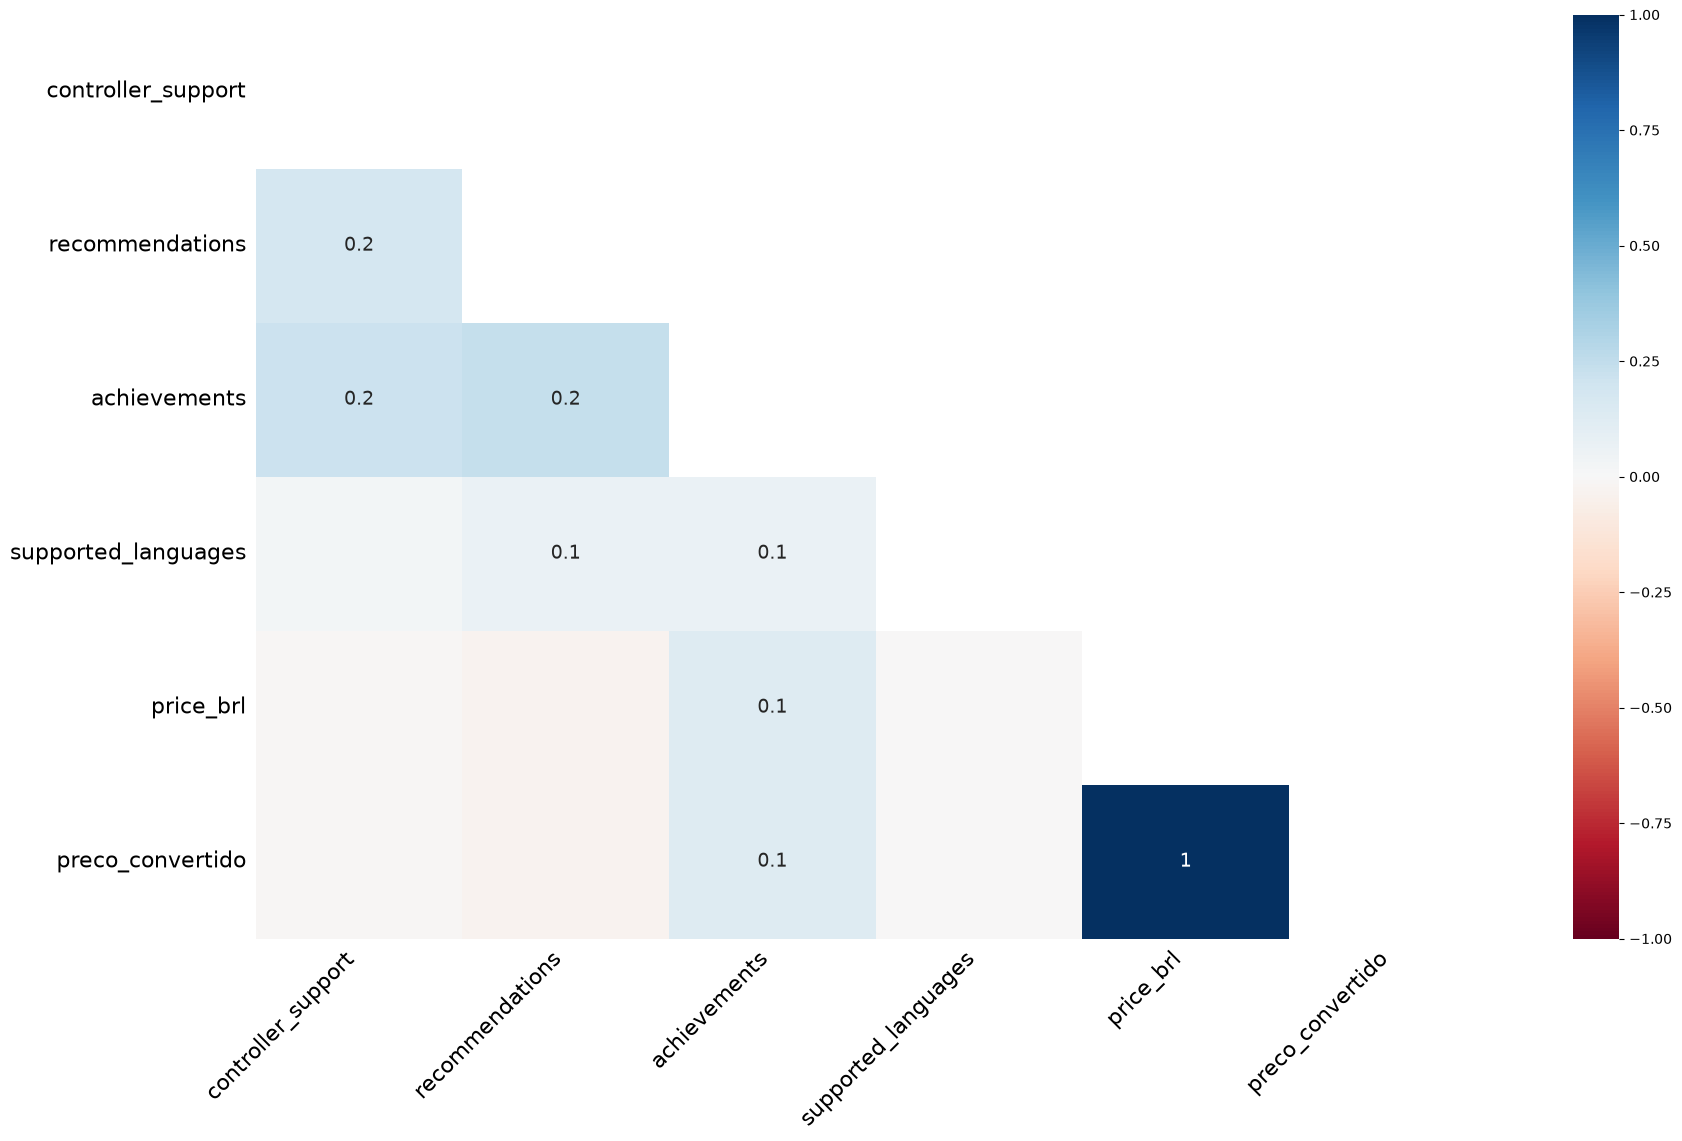

In [444]:
# ausencias

# Gráfico de calor de correlação de nulos
msno.heatmap(df_sem_duplicatas)
plt.show()

In [445]:
regra_respeitada = df_sem_duplicatas.loc[df_sem_duplicatas['price_brl'].isna(), 'is_free'].all()

print(f"Todos os jogos com preço nulo são gratuitos? {regra_respeitada}")

Todos os jogos com preço nulo são gratuitos? False


In [446]:
# Filtra os jogos com preço nulo onde is_free NÃO é True
excecoes = df_sem_duplicatas[(df_sem_duplicatas['price_brl'].isna()) & (df_sem_duplicatas['is_free'] != True)]

print(f"Quantidade de exceções encontradas: {len(excecoes)}")
display(excecoes[['name', 'is_free', 'price_brl']].head(10))

Quantidade de exceções encontradas: 22


,name,is_free,price_brl
151,Half-Life 2: Episode Two,False,NaN
292,Forza Horizon 4: Car Pass,False,NaN
299,Mark of the Ninja,False,NaN
324,VillageRhapsody,False,NaN
412,Yakuza 0,False,NaN
420,Touhou Koumakyou: New Classic - the Embodiment...,False,NaN
445,Half-Life 2: Episode One,False,NaN
446,The Witcher 3: Wild Hunt - Blood and Wine,False,NaN
454,Oats Studios - Volume 1,False,NaN
559,Neighbours from Hell Compilation,False,NaN


In [447]:
df_sem_duplicatas["controller_support"] = df_sem_duplicatas[
    "controller_support"
].fillna("sem suporte")

display(perfil_dataframe(df_sem_duplicatas))

,tipo_dado,qtd_nulos,porc_nulos,qtd_unicos
appid,str,0,0.000000,997
type,str,0,0.000000,7
name,str,0,0.000000,997
required_age,str,0,0.000000,9
is_free,bool,0,0.000000,2
dlc,Int64,0,0.000000,31
packages,Int64,0,0.000000,6
controller_support,str,0,0.000000,2
developers,str,0,0.000000,770
publishers,str,0,0.000000,687


In [448]:
colunas = ['achievements', 'recommendations', 'price_brl']

df_tratado = df_sem_duplicatas.copy()
df_tratado['achievements'] = df_tratado['achievements'].astype('float64')
df_tratado['recommendations'] = df_tratado['recommendations'].astype('float64')

for col in colunas:

    df_tratado[f'{col}_imputada'] = df_tratado[col].isna()

    q1 = df_tratado[col].quantile(0.25)
    q3 = df_tratado[col].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    
    
    dentro_do_iqr = df_tratado[col].between(limite_inferior, limite_superior)
    mediana = df_tratado.loc[dentro_do_iqr, col].median()

    # imputa somente os nulos
    df_tratado[col] = df_tratado[col].fillna(mediana)


df_tratado['preco_convertido'] = df_tratado['preco_convertido'].fillna(False)
# restaura os tipos originais
df_tratado['achievements'] = df_tratado['achievements'].round().astype('int64')
df_tratado['recommendations'] = df_tratado['recommendations'].round().astype('int64')
df_tratado['price_brl'] = df_tratado['price_brl'].astype('float64')

print(df_tratado[colunas].isna().sum())
print(df_tratado[colunas].dtypes)

achievements       0
recommendations    0
price_brl          0
dtype: int64
achievements         int64
recommendations      int64
price_brl          float64
dtype: object


In [449]:
display(df_tratado[['achievements', 'achievements_imputada', 
                    'recommendations', 'recommendations_imputada', 
                    'price_brl', 'price_brl_imputada']].head(10))

,achievements,achievements_imputada,recommendations,recommendations_imputada,price_brl,price_brl_imputada
0,51,False,390616,False,32.99,False
1,49,False,894890,False,24.99,False
2,17,False,298348,False,20.69,False
3,15,False,173695,False,32.99,False
4,243,False,251776,False,27.44,False
5,97,False,7472,True,0.00,False
6,49,False,285838,False,137.44,False
7,82,False,55877,False,82.44,False
8,17,False,945528,False,16.50,False
9,101,False,816863,False,32.99,False


In [450]:
df_tratado["supported_languages"] = df_tratado["supported_languages"].fillna("Não informado")

In [451]:
display(perfil_dataframe(df_tratado))
display(df_tratado[df_tratado["required_age"]=="0"].count())

,tipo_dado,qtd_nulos,porc_nulos,qtd_unicos
appid,str,0,0.0,997
type,str,0,0.0,7
name,str,0,0.0,997
required_age,str,0,0.0,9
is_free,bool,0,0.0,2
dlc,Int64,0,0.0,31
packages,Int64,0,0.0,6
controller_support,str,0,0.0,2
developers,str,0,0.0,770
publishers,str,0,0.0,687


appid                       58
type                        58
name                        58
required_age                58
is_free                     58
dlc                         58
packages                    58
controller_support          58
developers                  58
publishers                  58
categories                  58
genres                      58
recommendations             58
achievements                58
release_date                58
supported_languages         58
price_brl                   58
preco_convertido            58
achievements_imputada       58
recommendations_imputada    58
price_brl_imputada          58
dtype: int64

In [452]:

df_tratado["Indie"] = (
    df_tratado["genres"].astype(str).str.lower().str.contains("indie", regex=False)
)

display(df_tratado[df_tratado["Indie"] == True][["name", "genres", "Indie"]].head(5))

,name,genres,Indie
1,Stardew Valley,"Indie, RPG, Simulation",True
2,People Playground,"Action, Casual, Indie, Simulation",True
4,Vampire Survivors,"Action, Casual, Indie, RPG",True
5,HoloCure - Save the Fans!,"Action, Adventure, Casual, Indie",True
6,Hades,"Action, Indie, RPG",True


In [453]:

df_tratado["release_date"] = pd.to_datetime(
    df_tratado["release_date"], format="mixed"
)

In [454]:
linhas_nulas = df_tratado[df_tratado["release_date"].isna()]
display(linhas_nulas[["appid", "name", "release_date"]])


,appid,name,release_date
299,214560,Mark of the Ninja,NaT


In [463]:

# 1. Criação do Contrato (Schema)

TRUSTED = Path("../data/trusted/jogos_tratados.jsonl")
QUARENTENA = Path("../data/quarentena/jogos_rejeitados.jsonl")

CONTRATO = DataFrameSchema(
    {
        # Acurácia: tipo correto e chave que não repete
        "appid": Column(str, unique=True, nullable=False),
        "name": Column(str, nullable=False),
        "is_free": Column(bool, nullable=False),
        "recommendations": Column(int, nullable=False),
        "achievements": Column(int, nullable=False),
        "price_brl": Column(float, nullable=False),
        # Consistência: domínio fechado
        "type": Column(
            str,
            Check.isin(["game"], error="type_fora_dominio"),
            nullable=False,
        ),
        "required_age": Column(
            str,
            Check.isin(
                ["L", "6", "10", "12", "14", "16", "18"],
                error="required_age_fora_dominio",
            ),
            nullable=False,
        ),
        # Completude: nullable declarado coluna a coluna
        "dlc": Column(pa.Int64, nullable=False),
        "packages": Column(pa.Int64, nullable=False),
        "release_date": Column(object, nullable=False),
        "controller_support": Column(str, nullable=False),
        "developers": Column(str, nullable=False),
        "publishers": Column(str, nullable=False),
        "categories": Column(str, nullable=False),
        "genres": Column(str, nullable=False),
        "supported_languages": Column(str, nullable=False),
        "preco_convertido": Column(bool, nullable=False),
        "achievements_imputada": Column(bool, nullable=False),
        "recommendations_imputada": Column(bool, nullable=False),
        "price_brl_imputada": Column(bool, nullable=False),
        "Indie": Column(bool, nullable=False),
    },
    # Regras de negócio: nível da tabela, envolvendo duas colunas
    checks=[
        Check(
            lambda df: df["is_free"] == (df["price_brl"] == 0),
            error="preco_gratuidade_incoerente",
        ),
        Check(
            lambda df: ~(df["preco_convertido"] & df["price_brl_imputada"]),
            error="preco_convertido_e_imputado",
        ),
    ],
    coerce=True,
    strict=True,
)


def validar(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Devolve (aprovado, rejeitado). Não grava nada em disco."""
    df = df.reset_index(drop=True)

    try:
        aprovado = CONTRATO.validate(df, lazy=True)
        rejeitado = pd.DataFrame({"appid": [], "motivos": []})
        return aprovado, rejeitado

    except pa.errors.SchemaErrors as erro:
        falhas = erro.failure_cases

        # Falha sem linha é da estrutura (coluna nova, coluna faltando...):
        # não dá para isolar linha, então o pipeline para.
        if falhas["index"].isna().any():
            raise SystemExit(
                "contrato quebrado na estrutura, nada foi gravado:\n"
                f"{falhas[falhas['index'].isna()]}"
            )

        # failure_cases lista células; agrupar por index devolve linhas
        motivos = falhas.groupby("index")["check"].agg(
            lambda s: ", ".join(sorted(set(s.astype(str))))
        )

        rejeitado = pd.DataFrame(
            {
                "appid": df.loc[motivos.index, "appid"].to_numpy(),
                "motivos": motivos.to_numpy(),
            }
        )

        # Revalida o que sobrou: a trusted só recebe o que passou no contrato
        aprovado = CONTRATO.validate(df.drop(index=motivos.index))
        return aprovado, rejeitado


def main(df_tratado: pd.DataFrame) -> None:
    aprovado, rejeitado = validar(df_tratado)

    TRUSTED.parent.mkdir(parents=True, exist_ok=True)
    aprovado.to_json(TRUSTED, orient="records", lines=True)

    if len(rejeitado):
        QUARENTENA.parent.mkdir(parents=True, exist_ok=True)
        rejeitado.to_json(QUARENTENA, orient="records", lines=True)

    print(f"trusted:    {len(aprovado)} linhas -> {TRUSTED}")
    print(f"quarentena: {len(rejeitado)} linhas -> {QUARENTENA}")


main(df_tratado)

trusted:    895 linhas -> ..\data\trusted\jogos_tratados.jsonl
quarentena: 102 linhas -> ..\data\quarentena\jogos_rejeitados.jsonl
